## Basic Functions and Definitions

In [45]:
# Library
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
%matplotlib inline

In [46]:
# Epidemiological and Diffusion Parameters
PARAMETERS = { 'β' : 0.50, # Infection rate
               'η' : 0.27, # Birth/growth rate
               'μ' : 0.25, # Mortality rate
               'κ' : 1000, # Carrying capacity
               'Ds': 0.10, # Susceptible spread
               'Di': 2.00, # Infected spread
               'Dc': 0.02  # Cross-diffusion
}

In [47]:
# Definition of Laplacian
def Laplacian(F, space_step):
    return (F[:-2, 1:-1] + F[1:-1, :-2] + F[2:, 1:-1] + F[1:-1, 2:] - 4 * F[1:-1, 1:-1]) / (space_step**2)

In [48]:
# Pattern Visualization
def Patterns(F, ax = None):
    if ax is None:
        fig, ax = plt.subplots()
    ax.imshow(F, cmap = 'viridis', extent = [-1, 1, -1, 1], origin = 'lower')
    ax.set_axis_off()

## Functions Applied to the Reaction-Diffusion Process

In [49]:
# Define the equilibrium points
def Equilibrium(β, η, μ, κ):
    S_star = κ * (η - β + μ) / η
    I_star = κ * (η - β + μ) * (β - μ) / (η * μ)
    return S_star, I_star

In [50]:
# Reation Setups
def Reaction(S, I, β, η, μ, κ):

    # Logistic growth of susceptible individuals (limited by κ)
    growth = η * S * (1 - S / κ)
    # Infection strength
    infect = β * S * I / (S + I + 1e-12)

    # Balance for each field
    dS = growth - infect
    dI = infect - μ * I

    # Return the results
    return dS, dI

In [51]:
# Basic Reaction-Diffusion Data
def ReactionDiffusion1d(size, space_step, time_step, iterations, parameters, seed, save_every):

    # Calls the equilibrium points
    S_star, I_star = Equilibrium(parameters['β'], parameters['η'], parameters['μ'], parameters['κ'])

    # Initialize the variables
    np.random.seed(seed)
    S = S_star + 0.01 * (np.random.rand(size) - 0.5) * S_star
    I = I_star + 0.01 * (np.random.rand(size) - 0.5) * I_star

    # Initialize the spatial e temporal vectors
    history_I, time_points = [], []

    for step in range(iterations + 1):
        # Boundary contour
        S_ext = np.pad(S, (1, 1), mode = 'edge')
        I_ext = np.pad(I, (1, 1), mode = 'edge')

        # Iterate and store steps in time and space
        lap_S = (S_ext[:-2] - 2*S + S_ext[2:]) / (space_step**2)
        lap_I = (I_ext[:-2] - 2*I + I_ext[2:]) / (space_step**2)

        dS_reac, dI_reac = Reaction(S, I, parameters['β'], parameters['η'], parameters['μ'], parameters['κ'])

        dS = dS_reac + parameters['Ds'] * lap_S + parameters['Dc'] * lap_I
        dI = dI_reac + parameters['Di'] * lap_I

        S += time_step * dS
        I += time_step * dI

        if step % save_every == 0:
            history_I.append(I.copy())
            time_points.append(step * time_step)

    return np.array(history_I), np.array(time_points)

In [52]:
# Reation-Diffusion Simulation: Finite Diference Method
def FiniteDifferenceMethod(shape, space_step, time_step, interations, parameters, seed):
    # Calls the equilibrium points
    S_star, I_star = Equilibrium(parameters['β'], parameters['η'], parameters['μ'], parameters['κ'])

    # Initialize the variables
    np.random.seed(seed)
    S = S_star + 0.01 * (np.random.rand(*shape) - 0.5) * S_star
    I = I_star + 0.01 * (np.random.rand(*shape) - 0.5) * I_star

    # Iterations itself
    for step in range(interations):
        Sc, Ic = S[1:-1, 1:-1], I[1:-1, 1:-1]

        # Calculate the Laplacian (spread!)
        lap_S = Laplacian(S, space_step)
        lap_I = Laplacian(I, space_step)

        # Define the reaction term
        dS_reac, dI_reac = Reaction(Sc, Ic, parameters['β'], parameters['η'], parameters['μ'], parameters['κ'])

        # Calculate the variables value
        S[1:-1, 1:-1] = Sc + time_step * (dS_reac + parameters['Ds'] * lap_S + parameters['Dc'] * lap_I)
        I[1:-1, 1:-1] = Ic + time_step * (dI_reac + parameters['Di'] * lap_I)

        # Neumann Boundary Conditions
        for M in (S, I):
            M[0, :], M[-1, :] = M[1, :], M[-2, :]
            M[:, 0], M[:, -1] = M[:, 1], M[:, -2]

    # Return the values
    return S, I

## Plotting Functions

In [53]:
# Plotting: Bifurcation Diagrams
def BifurcationDiagram(parameters):
    # Define η values
    η_vals = np.linspace(0.10, 0.45, 500)
    β, Ds, Di, Dc = parameters['β'], parameters['Ds'], parameters['Di'], parameters['Dc']

    # Hopf Bifurcation (time)
    hopf      = β - η_vals
    term_sqrt = - η_vals * β * Dc * Ds + (η_vals**2) * Ds * Di + (η_vals**2) * Dc * Ds
    # Turing Bifurcation (space)
    turing    = (η_vals - β) * (-η_vals*(Ds + Dc + Di) + β*(Dc - Di) + 2*np.sqrt(np.maximum(0, term_sqrt))) / (β * Di)

    # Figure setup
    plt.figure(figsize=(8, 6))
    plt.plot(η_vals, hopf,   linestyle = '--', color = 'navy',    linewidth=2, label = 'Hopf Bifurcation')
    plt.plot(η_vals, turing, linestyle = '--', color = '#f06c4c', linewidth=2, label = 'Turing Bifurcation')
    # Highlights the bifurcation regions
    plt.fill_between(η_vals, 0,    hopf,   color = 'whitesmoke',     alpha=0.5) # no desease!
    plt.fill_between(η_vals, hopf, turing, color = 'lightsteelblue', alpha=0.5) # turing region
    plt.fill_between(η_vals, turing, 0.45, color = 'moccasin',       alpha=0.5) # instability
    # Grid and axes setups
    plt.xlim(0.10, 0.45)
    plt.ylim(0, 0.45)
    plt.xlabel(r'Mortality rate of those infected ($\mu$)', fontsize=14)
    plt.ylabel(r'Birth rate ($\eta$)',                      fontsize=14)
    plt.legend(loc = 'lower left', fontsize=12)
    plt.grid(True, linestyle = ':', alpha = 0.6)
    plt.tight_layout()
    plt.show()

In [54]:
# Plotting: Spatial Profile
def SpatialProfile(history_I, time_points, t1, t2):
    # Define the spatial points
    idx1 = np.searchsorted(time_points, t1)
    idx2 = np.searchsorted(time_points, t2)

    # Figure setup
    plt.figure(figsize=(9, 5))
    x = np.arange(history_I.shape[1])
    plt.plot(x, history_I[idx1], linestyle = '--', color = 'navy', linewidth = 1.5, label = f'$t = {t1}$')
    plt.plot(x, history_I[idx2], linestyle = '-',  color = 'navy', linewidth = 1.5, label = f'$t = {t2}$')
    # Axis setup
    plt.xlabel('Space ($x$)',                  fontsize = 14)
    plt.ylabel('Infection Density ($I$)', fontsize = 14)
    # Graph setup
    plt.legend(loc='upper right', fontsize=12)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.show()

In [55]:
# Plotting: Temporal Evolution
def TimeEvolution(history_I, time_points, idx_L1, idx_L2):
    # Figure setup
    plt.figure(figsize=(9, 5))
    plt.plot(time_points, history_I[:, idx_L1], linestyle = '-',  color = '#f06c4c', linewidth = 1.5, label = f'$x_1 = {idx_L1}$')
    plt.plot(time_points, history_I[:, idx_L2], linestyle = '--', color = '#f06c4c', linewidth = 2.0, label = f'$x_2 = {idx_L2}$')
    # Axis setup
    plt.xlabel('Time ($t$)',              fontsize = 14)
    plt.ylabel('Infection Density ($I$)', fontsize = 14)
    # Graph setup
    plt.legend(loc = 'upper right', fontsize = 12)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.show()

## Functions call

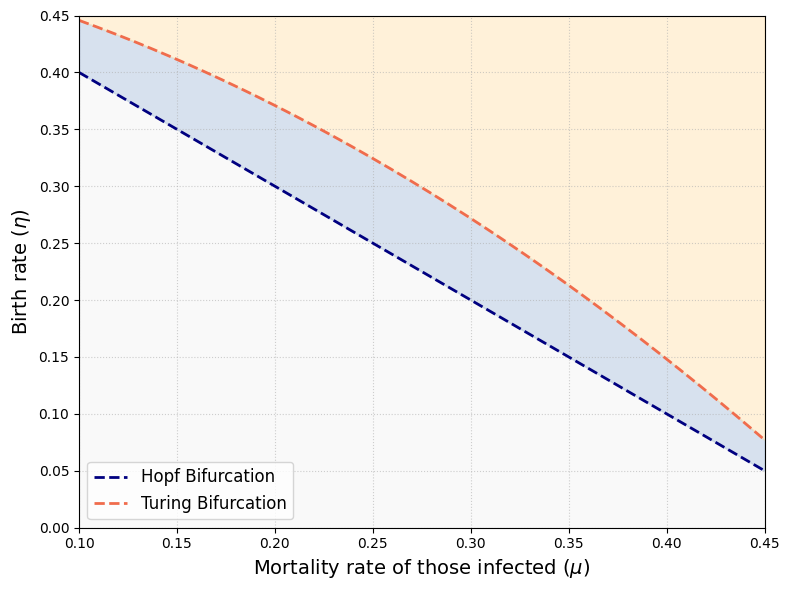

In [56]:
# Bifurcations Diagram
BifurcationDiagram(PARAMETERS)

In [57]:
# General 1d Simulation

# Parameters definition
parameters_spatial = PARAMETERS.copy()
parameters_spatial['η'] = 0.30
# Calls
space1d, time1d = ReactionDiffusion1d(200, 1.0, 0.04, 175000, parameters_spatial, 12, 250)
SpatialProfile(space1d, time1d, 1000)

TypeError: SpatialProfile() missing 1 required positional argument: 't2'

In [ ]:
# Spatial Profile
x_spatialprofile, t_spatialprofile = ReactionDiffusion1d(200, 1.0, 0.04, 5000, PARAMETERS, 0, 1)
SpatialProfile(x_spatialprofile, t_spatialprofile, 140, 180)

In [ ]:
# Time Evolution
x_timeevolution, t_timeevolution = ReactionDiffusion1d(100, 1.0, 0.04, 25000, PARAMETERS, 0, 1)
TimeEvolution(x_timeevolution, t_timeevolution, 36, 61)